# A2 corregido: Random Forest (correcciones i y ii)

Cambios respecto a `A2_RandomForest.ipynb` (el original queda intacto):
1. Se conserva `participant_id` para saber de qué paciente es cada muestra.
2. El `train_test_split` por muestra se reemplaza por los pliegues comunes por paciente
   (`pliegues_por_paciente.csv`). Ninguna paciente tiene muestras en entrenamiento y prueba
   a la vez, lo que también elimina la fuga de información del punto ii.
3. La probabilidad de cada paciente es el promedio de sus muestras. Se reportan AUC-ROC y AUC-PR.

Hiperparámetros iguales al original (100 árboles, sin límite de profundidad, `class_weight='balanced'`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

sys.path.insert(0, os.path.abspath('.'))
from comun import (leer_datos, RESULTADOS, ETIQUETA, cargar_pliegues, iterar_pliegues,
                   promedio_por_paciente, umbral_sens_igual_espec, metricas)
RESULTADOS.mkdir(exist_ok=True)

metadata = leer_datos('metadata')
taxonomy = leer_datos('taxonomy_relabd.species')

meta_subset = metadata[['specimen', 'participant_id', ETIQUETA]].copy()   # CAMBIO: + participant_id
full_data = pd.merge(meta_subset, taxonomy, on='specimen')

X = full_data.drop(columns=['specimen', 'participant_id', ETIQUETA])
y = full_data[ETIQUETA].astype(int).values
pacientes = full_data['participant_id'].values
print(X.shape, '| pacientes:', len(set(pacientes)))

(1895, 2118) | pacientes: 616


In [2]:
pliegues = cargar_pliegues()
filas, predicciones, importancias = [], [], []
for rep, fold, ids_tr, ids_te in iterar_pliegues(pliegues):
    tr, te = np.isin(pacientes, list(ids_tr)), np.isin(pacientes, list(ids_te))
    rf_model = RandomForestClassifier(n_estimators=100, max_depth=None, class_weight='balanced',
                                      random_state=42, n_jobs=-1)
    rf_model.fit(X[tr], y[tr])
    prob_muestra = rf_model.predict_proba(X[te])[:, 1]
    pp = promedio_por_paciente(pacientes[te], y[te], prob_muestra)
    umbral = umbral_sens_igual_espec(pp.y, pp.prob)   # misma regla para los tres modelos (punto iii)
    filas.append(dict(modelo='Random Forest', rep=rep, fold=fold, **metricas(pp.y, pp.prob, umbral)))
    predicciones.append(pp.assign(rep=rep, fold=fold))
    importancias.append(rf_model.feature_importances_)

pd.concat(predicciones).to_csv(RESULTADOS / 'pred_A2.csv', index=False)
res = pd.DataFrame(filas)
res.to_csv(RESULTADOS / 'metricas_A2.csv', index=False)
res[['auc_roc', 'auc_pr', 'accuracy', 'precision', 'recall', 'f1', 'umbral']].agg(['mean', 'std']).round(3)

,auc_roc,auc_pr,accuracy,precision,recall,f1,umbral
mean,0.780,0.774,0.703,0.645,0.703,0.672,0.371
std,0.038,0.041,0.034,0.038,0.036,0.037,0.036


                     Bacteria  Importance       Std
1050  Lactobacillus crispatus    0.021682  0.001570
1062      Lactobacillus iners    0.019374  0.001444
1063   Lactobacillus jensenii    0.018571  0.001502
2075                Weissella    0.018009  0.001725
823                Firmicutes    0.014895  0.001646
1975      Terrabacteria group    0.013359  0.001535
1040            Lactobacillus    0.012581  0.001235
1451      Peptoniphilus harei    0.012491  0.002280
1080  Lactobacillus vaginalis    0.012031  0.001336
1529         Prevotella bivia    0.011297  0.001209


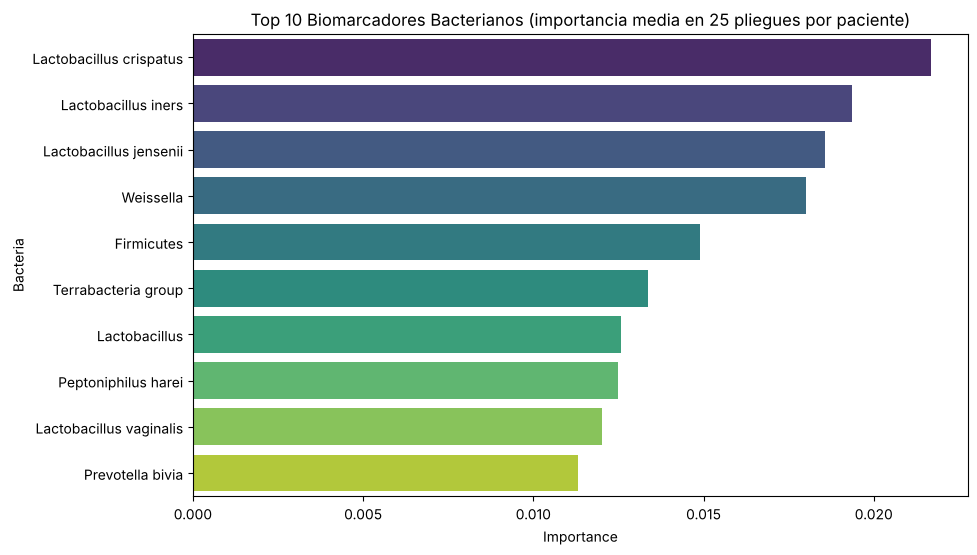

In [3]:
# Importancia media de cada especie en los 25 pliegues
imp = pd.DataFrame({'Bacteria': X.columns, 'Importance': np.mean(importancias, axis=0),
                    'Std': np.std(importancias, axis=0)})
top_10_bacteria = imp.sort_values('Importance', ascending=False).head(10)
top_10_bacteria.to_csv(RESULTADOS / 'top10_importancia_A2.csv', index=False)
print(top_10_bacteria)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Bacteria', hue='Bacteria', data=top_10_bacteria, palette='viridis', legend=False)
plt.title('Top 10 Biomarcadores Bacterianos (importancia media en 25 pliegues por paciente)')
plt.show()